## 1. Problem and metric

Each training example is a cryo-electron tomogram, a 3D image of a bacterium. The task is to decide whether the tomogram contains a flagellar motor and, if it does, to predict the motor centre as (z, y, x) voxel coordinates. Predictions are scored with the F2 score: a prediction within 1000 Å of a true motor centre is a hit (TP); a prediction that is too far away, or no prediction, is a missed motor (FN); and a prediction on a tomogram without a motor is a false alarm (FP). With β = 2, recall weighs more than precision, so missing a motor costs more than a false alarm. Because the threshold is in ångströms, distances in voxels must be converted using each tomogram's voxel spacing.

In [1]:
import pandas as pd

df = pd.read_csv("../../data/train_labels.csv")
print(df.shape)
print(df.columns.tolist())
print("Farklı tomogram sayısı:", df["tomo_id"].nunique())
df.head()

(737, 10)
['row_id', 'tomo_id', 'Motor axis 0', 'Motor axis 1', 'Motor axis 2', 'Array shape (axis 0)', 'Array shape (axis 1)', 'Array shape (axis 2)', 'Voxel spacing', 'Number of motors']
Farklı tomogram sayısı: 648


,row_id,tomo_id,Motor axis 0,Motor axis 1,Motor axis 2,Array shape (axis 0),Array shape (axis 1),Array shape (axis 2),Voxel spacing,Number of motors
0,0,tomo_003acc,-1.0,-1.0,-1.0,500,1912,1847,6.5,0
1,1,tomo_00e047,169.0,546.0,603.0,300,959,928,15.6,1
2,2,tomo_00e463,235.0,403.0,137.0,500,924,956,19.7,6
3,3,tomo_00e463,243.0,363.0,153.0,500,924,956,19.7,6
4,4,tomo_00e463,222.0,379.0,144.0,500,924,956,19.7,6


In [2]:
%load_ext autoreload
%autoreload 2

import sys
sys.path.append("../..")

from src import data

labels = data.load_labels("../../data/train_labels.csv")   # her satır bir motor
tomos = data.tomogram_table(labels)                        # her satır bir tomogram

print(len(labels), len(tomos))
tomos.head()

737 648


,tomo_id,shape_z,shape_y,shape_x,voxel_spacing,n_motors,has_motor
0,tomo_003acc,500,1912,1847,6.5,0,False
1,tomo_00e047,300,959,928,15.6,1,True
2,tomo_00e463,500,924,956,19.7,6,True
3,tomo_01a877,300,960,928,13.1,1,True
4,tomo_02862f,300,959,928,15.6,1,True


## 2. Data description

- **Instance:** one tomogram (a 3D cryo-ET volume). **Cardinality:** n = 648 training tomograms.
- **Features:** for a model, the voxel intensities of the tomogram (the image itself). The label file adds per-tomogram metadata (shape, voxel spacing) and the targets (motor coordinates).
- **Label file:** `train_labels.csv` has 737 rows, one per motor (tidy data: one observation per row). Tomograms without a motor appear once, with coordinates −1.
- **Data type:** the raw tomograms are stacks of 2D JPEG slices (unstructured image data); the label file is structured tabular data.

| Column | Meaning | Level of measurement | Why |
|---|---|---|---|
| `row_id` | row number | nominal | an identifier; only equal / not equal is meaningful |
| `tomo_id` | tomogram name | nominal | an identifier; only equal / not equal is meaningful |
| `Motor axis 0/1/2` (z, y, x) | motor centre, in voxels | interval | differences (distances) are meaningful, but zero is just the corner of the array, so ratios are not |
| `Array shape (axis 0/1/2)` | tomogram size, in voxels | ratio | a count of voxels with a true zero; 1912 is twice 956 |
| `Voxel spacing` | size of one voxel, in Å | ratio | a physical length with a true zero; 19.7 Å is about 3× 6.5 Å |
| `Number of motors` | motors in the tomogram | ratio (discrete) | a count with a true zero |
| `has_motor` (derived) | motor present or not | asymmetric binary | "motor present" is the outcome that matters; the F2 metric penalises a missed motor more than a false alarm |

- **Sentinel values:** a coordinate of −1 means "no motor", not a real position. These rows must be excluded (using `has_motor`) before computing statistics on motor positions; otherwise, for example, the mean position is pulled towards −1.

 ## 3. Metadata EDA

In [3]:
tomos["has_motor"].value_counts()

has_motor
True     362
False    286
Name: count, dtype: int64

**Observation:** 362 of the 648 training tomograms (56%) contain at least one motor and 286 (44%) contain none, so the two classes are fairly balanced.

In [4]:
tomos["n_motors"].value_counts().sort_index()

n_motors
0     286
1     313
2      30
3       6
4       9
6       3
10      1
Name: count, dtype: int64

In [5]:
print("n_motors column sums to:", tomos["n_motors"].sum())
print("Motors with coordinates:", labels["has_motor"].sum())

n_motors column sums to: 455
Motors with coordinates: 451


**Observation:** Most tomograms with a motor contain exactly one: 313 of 362 (86%). The other 49 contain between 2 and 10 motors. Since a submission has only one predicted point per tomogram, a model only needs to find one of the motors in these tomograms (this is how our F2 function in `src/utils.py` scores them). The `n_motors` column sums to 455, but the CSV has coordinates for only 451 motors, so 4 motors are counted but not labelled.

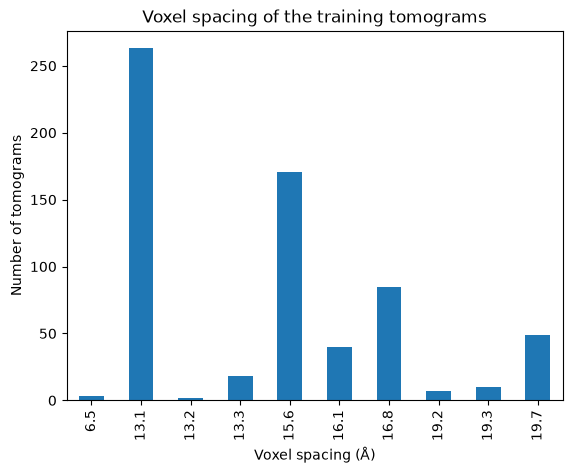

In [6]:
import matplotlib.pyplot as plt

from src import plots

plots.voxel_spacing(tomos)
plt.show()

In [7]:
tomos["voxel_spacing"].value_counts().sort_index()

voxel_spacing
6.5       3
13.1    263
13.2      2
13.3     18
15.6    171
16.1     40
16.8     85
19.2      7
19.3     10
19.7     49
Name: count, dtype: int64

**Observation:** Voxel spacing takes only 10 distinct values, from 6.5 Å to 19.7 Å; most tomograms use 13.1 Å (263) or 15.6 Å (171). Because the spacing differs between tomograms, the 1000 Å threshold corresponds to about 154 voxels in the finest tomograms but only about 51 voxels in the coarsest ones, so distances must be compared in ångströms, not in voxels.

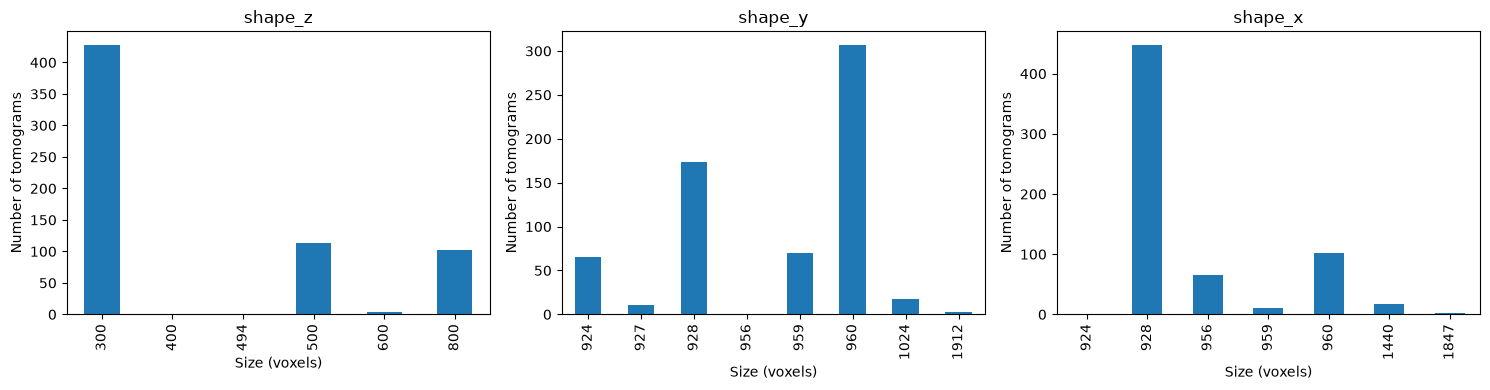

In [8]:
plots.tomogram_sizes(tomos)
plt.show()

In [9]:
for col in ["shape_z", "shape_y", "shape_x"]:
    print(tomos[col].value_counts().sort_index(), "\n")

shape_z
300    428
400      1
494      1
500    113
600      3
800    102
Name: count, dtype: int64 

shape_y
924      65
927      11
928     173
956       1
959      70
960     307
1024     18
1912      3
Name: count, dtype: int64 

shape_x
924       1
928     448
956      65
959      11
960     102
1440     18
1847      3
Name: count, dtype: int64 



In [10]:
tomos[tomos["shape_y"] == 1912]

,tomo_id,shape_z,shape_y,shape_x,voxel_spacing,n_motors,has_motor
0,tomo_003acc,500,1912,1847,6.5,0,False
504,tomo_c77de0,494,1912,1847,6.5,0,False
639,tomo_fc90fd,500,1912,1847,6.5,0,False


**Observation:** Tomograms do not share a single size. Along z most have 300 slices (428), the rest mostly 500 (113) or 800 (102); in y and x most are 924–960 voxels, with two groups of outliers: 1024 × 1440 (18 tomograms) and 1912 × 1847 (3). The 3 largest are exactly the tomograms with the smallest voxel spacing (6.5 Å), so in physical size (≈12,400 Å) they match the others: a larger array means a finer resolution, not a larger sample. None of these 3 contains a motor, so the training set has no positive example at this resolution. Since sizes differ, a model needs fixed-size inputs (resizing or patches), and motor positions should be compared after normalising by tomogram size or converting to Å.

## 4. Motor location EDA

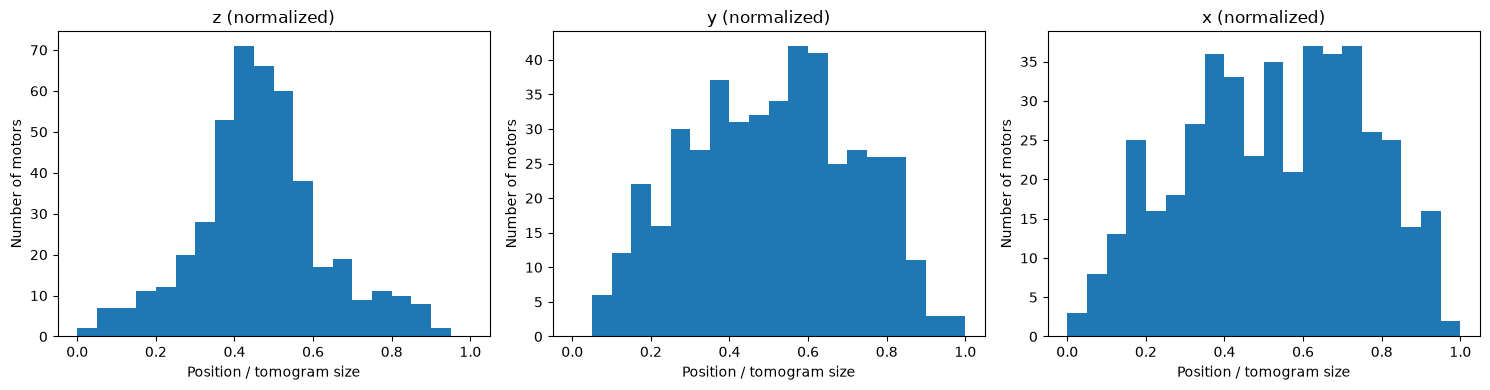

In [11]:
plots.position_histograms(labels)
plt.show()

In [12]:
motors = plots.normalized_positions(labels)
cols = ["z_norm", "y_norm", "x_norm"]

print(motors[cols].describe().round(2))
print("Motors within 5% of an edge:")
print(((motors[cols] < 0.05) | (motors[cols] > 0.95)).sum())

       z_norm  y_norm  x_norm
count  451.00  451.00  451.00
mean     0.47    0.51    0.53
std      0.16    0.21    0.23
min      0.00    0.06    0.03
25%      0.37    0.35    0.36
50%      0.46    0.51    0.53
75%      0.55    0.67    0.71
max      0.93    0.97    0.97
Motors within 5% of an edge:
z_norm    2
y_norm    3
x_norm    5
dtype: int64


**Observation:** Along z, motors cluster around the middle of the volume: half of them lie between 0.37 and 0.55 of the tomogram depth. Along y and x they are spread much more widely (the middle half covers 0.35–0.67 in y and 0.36–0.71 in x), so in the top view a motor can be almost anywhere. Very few motors lie within 5% of an edge (2 in z, 3 in y, 5 in x). B1 predicts the mean position (0.47, 0.51, 0.53) for every tomogram; the wide spread in y and x already suggests that this single point will usually be far from the true motor.

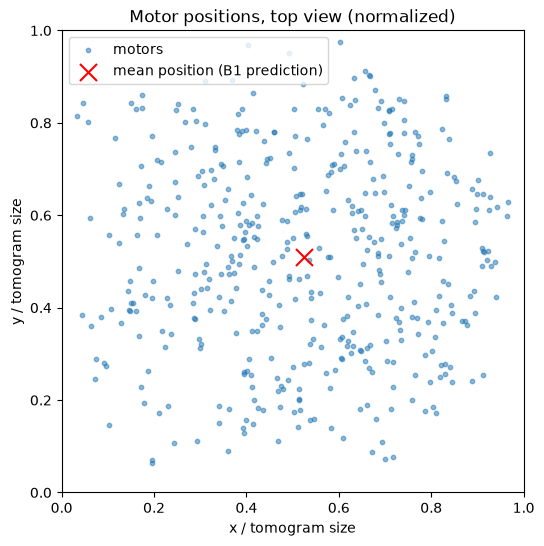

In [13]:
plt.figure(figsize=(6, 6))
plots.position_yx(labels)
plt.show()

In [14]:
corner = ((motors["x_norm"] < 0.15) | (motors["x_norm"] > 0.85)) & \
         ((motors["y_norm"] < 0.15) | (motors["y_norm"] > 0.85))
print("Motors in the four corners (outer 15% in both x and y):", corner.sum(), "of", len(motors))

Motors in the four corners (outer 15% in both x and y): 1 of 451


**Observation:** In the top view the motors are spread over most of the tomogram rather than concentrated around B1's prediction (red cross), which sits in the middle of a wide cloud. The corners are almost empty: the four corner regions (outer 15% in both x and y) cover 9% of the area but contain only 1 of the 451 motors, so the motors form a roughly round cloud around the centre. A single fixed point therefore cannot be close to most motors; the next plot measures how far it actually is.

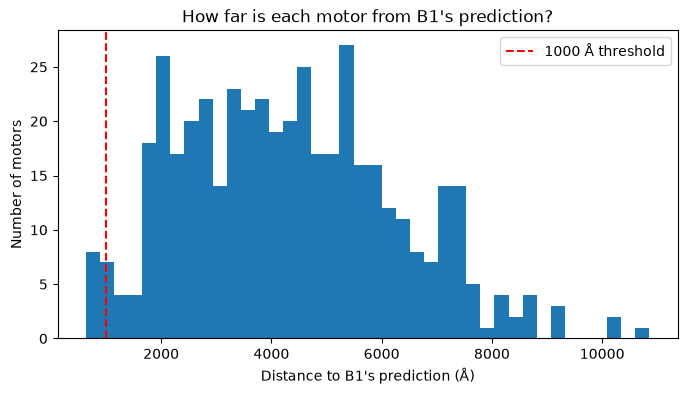

In [15]:
plt.figure(figsize=(8, 4))
plots.distance_to_mean_hist(labels)
plt.show()

In [16]:
dist = plots.distances_to_mean(labels)
print(dist.describe().round(0))
print("Motors within 1000 Å of B1's prediction:", (dist <= 1000).sum(), "of", len(dist))

motors["dist"] = dist
closest = motors.groupby("tomo_id")["dist"].min()   # per tomogram: the motor closest to B1's guess
print("Tomograms where B1 hits a motor:", (closest <= 1000).sum(), "of", len(closest))

count      451.0
mean      4329.0
std       1940.0
min        633.0
25%       2769.0
50%       4248.0
75%       5588.0
max      10857.0
dtype: float64
Motors within 1000 Å of B1's prediction: 9 of 451
Tomograms where B1 hits a motor: 8 of 362


**Observation:** This plot explains B1's score. The median distance from a motor to B1's prediction is about 4,250 Å, more than four times the 1000 Å threshold, and only 9 of the 451 motors (2%) fall within it. Counted per tomogram, as the metric does, B1 hits a motor in only 8 of the 362 tomograms that contain one (2.2%), and it raises a false alarm on every one of the 286 tomograms without a motor. This matches its very low Kaggle score (public 0.0104, see the README). A useful model has to locate each motor; guessing a typical position is not enough.

## 5. Image EDA

16 example tomograms, 12 with a motor
1000 Å in tomo_00e047 = 64 voxels


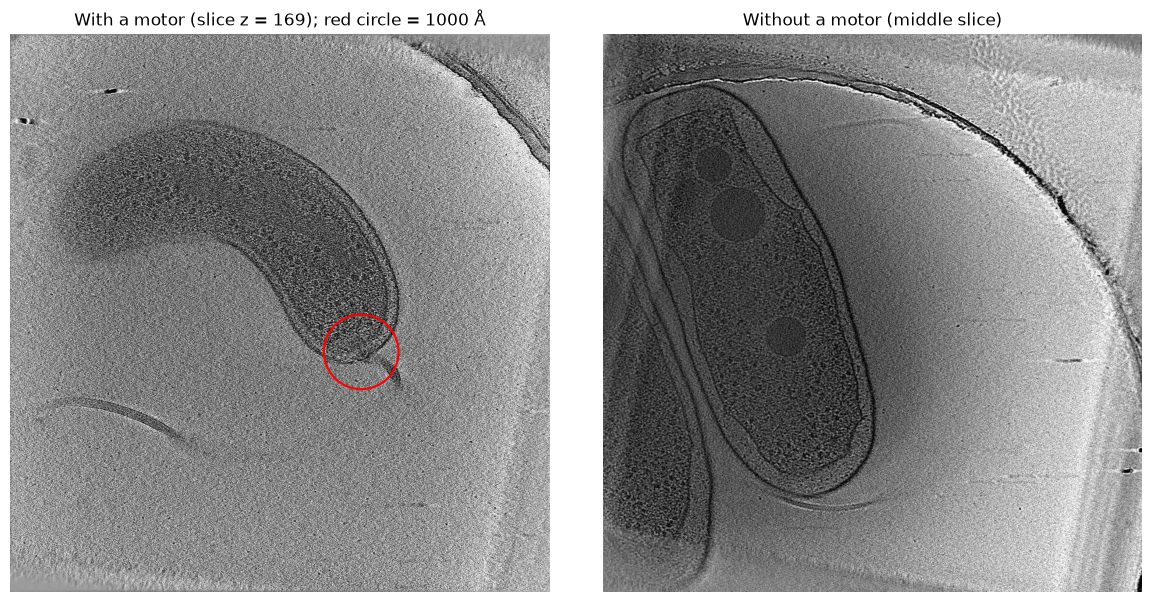

In [17]:
examples = plots.load_examples("../../data/examples")
spacing = tomos.set_index("tomo_id")["voxel_spacing"]
print(len(examples), "example tomograms,", sum("crops" in e for e in examples.values()), "with a motor")
print("1000 Å in tomo_00e047 =", round(1000 / spacing["tomo_00e047"]), "voxels")

plots.motor_vs_no_motor(examples["tomo_00e047"], examples["tomo_0308c5"], spacing["tomo_00e047"])
plt.show()

**Observation:** In tomo_00e047 the motor is a small structure at the end of the bacterium, where the flagellum (the thin "tail") leaves the cell. The red circle marks the 1000 Å threshold, only 64 voxels in this tomogram and much smaller than the bacterium, so a prediction has to land on the right end of the right cell. The slice without a motor (tomo_0308c5, same voxel spacing) also shows bacteria but no tail. One slice is not enough to rule out a motor, though, because a motor can lie in a different z slice, so a model has to search the whole 3D volume.

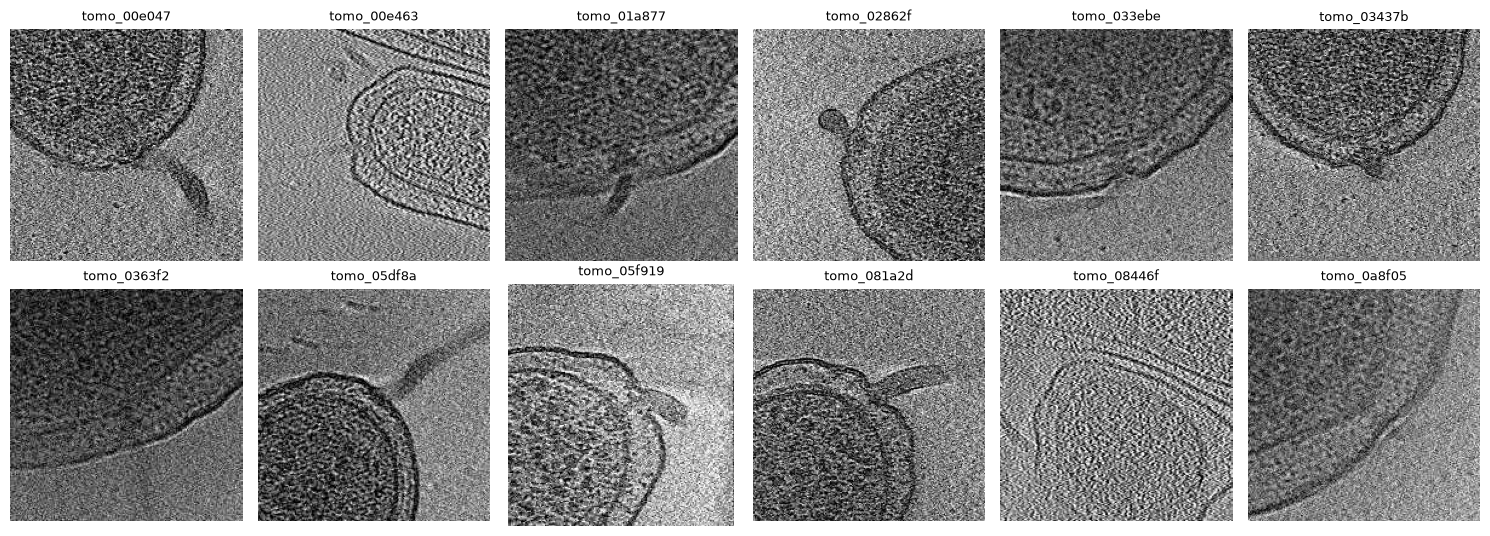

In [18]:
plots.crop_grid(examples)
plt.show()

**Observation:** The motors do not look alike. By eye, the motor is easy to spot in about 7 of the 12 crops (e.g. tomo_00e047, tomo_02862f, tomo_05df8a): it sits in the cell envelope at the base of the flagellum, the thin tail that leaves the cell. In the other 5 (tomo_00e463, tomo_033ebe, tomo_0363f2, tomo_08446f, tomo_0a8f05) it is small, faint or its tail is not in this slice. Contrast and noise also differ between tomograms. A detector cannot rely on one fixed template; it has to learn from many examples and should use neighbouring slices (3D context), not a single slice.

Downsampled volume: (37, 120, 116) | original: (300, 959, 928)
1000 Å in the downsampled volume = 8.0 voxels


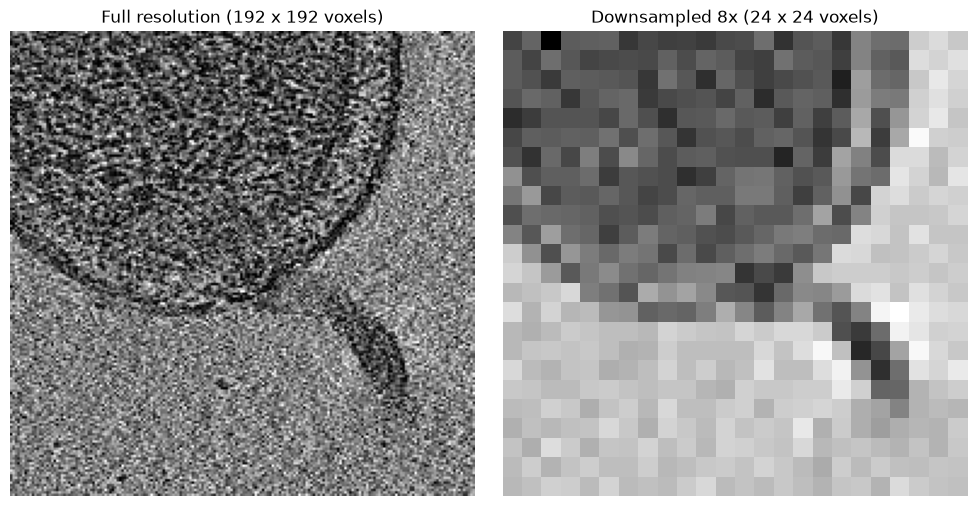

In [19]:
vol, meta = data.load_downsampled("../../data/downsampled/tomo_00e047.npz")
print("Downsampled volume:", vol.shape, "| original:", (meta["orig_z"], meta["orig_y"], meta["orig_x"]))
print("1000 Å in the downsampled volume =", round(1000 / (meta["voxel_spacing"] * meta["factor"]), 1), "voxels")

plots.full_vs_downsampled(examples["tomo_00e047"], vol, factor=meta["factor"])
plt.show()

**Observation:** After 8x downsampling, the same area shrinks from 192 × 192 to 24 × 24 voxels. The cell edge and the flagellum are still visible (the tail becomes a short dark streak of a few voxels), but the motor itself merges into the cell envelope and is no longer a separate structure. Knowing where to look makes it easy to spot; finding it without a hint in the whole 37 × 120 × 116 volume is much harder. Since 1000 Å is still 8 voxels at this scale, 8x is fine-grained enough for the metric, and the base of the tail at the cell edge is the main visual cue a model can use. Finer detail would need less downsampling or full-resolution patches around candidate locations.    

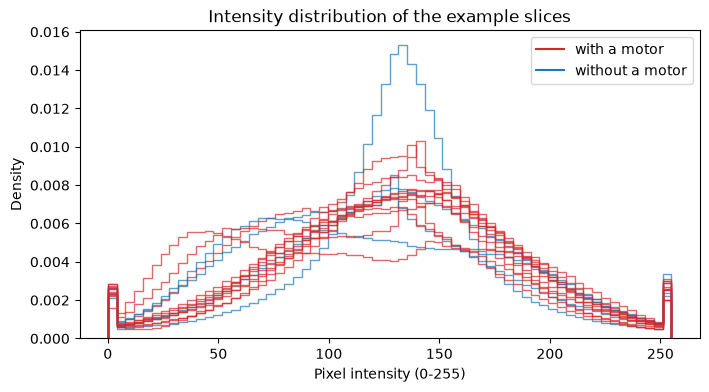

In [20]:
plt.figure(figsize=(8, 4))
plots.intensity_histograms(examples)
plt.show()

In [21]:
for name, e in examples.items():
    image = e["motor_slice"] if "crops" in e else e["middle_slice"]
    print(name, "motor   " if "crops" in e else "no motor", "mean", round(image.mean()), "std", round(image.std()))

tomo_003acc no motor mean 131 std 43
tomo_00e047 motor    mean 134 std 53
tomo_00e463 motor    mean 130 std 48
tomo_01a877 motor    mean 113 std 53
tomo_02862f motor    mean 132 std 54
tomo_0308c5 no motor mean 119 std 60
tomo_0333fa no motor mean 116 std 55
tomo_033ebe motor    mean 114 std 59
tomo_03437b motor    mean 134 std 53
tomo_0363f2 motor    mean 118 std 65
tomo_040b80 no motor mean 132 std 54
tomo_05df8a motor    mean 125 std 50
tomo_05f919 motor    mean 126 std 53
tomo_081a2d motor    mean 129 std 54
tomo_08446f motor    mean 136 std 50
tomo_0a8f05 motor    mean 134 std 52


**Observation:** Each line is the brightness distribution of one example slice. All slices look alike: most pixels are mid-grey, and the means overlap completely (113–136 with a motor, 116–132 without; standard deviations 43–65). The spikes at 0 and 255 come from the competition's preprocessing, which clipped each slice at its 1st and 99th percentiles before scaling it to 0–255. The single narrow blue peak is tomo_003acc, the only 6.5 Å tomogram here. Overall brightness therefore says nothing about whether a motor is present, since the motor covers only a tiny part of the slice; a model has to use local shape (the motor and tail at the cell edge), not global intensity.

## 6. Summary of observations

1. **Labels:** 648 training tomograms, 362 with a motor (56%) and 286 without, so the classes are fairly balanced. Most motor tomograms contain one motor (313 of 362); `n_motors` counts 4 motors that have no coordinates.
2. **Scale differs between tomograms:** voxel spacing ranges from 6.5 to 19.7 Å and sizes from 300 to 800 slices (up to 1912 × 1847 in y and x). The 1000 Å threshold is 51–154 voxels, so distances must be measured in Å, and a model needs resized inputs or fixed-size patches. The 3 finest-resolution tomograms (6.5 Å) contain no motor.
3. **Location cannot be guessed:** motors cluster around the middle in z but are spread over most of the y–x plane. A fixed guess (B1) is within 1000 Å of only 9 of 451 motors (median distance ≈ 4,250 Å), which explains its F2 of about 0.01. → In Assignment 2 the model must find the motor from the image content.
4. **What a motor looks like:** a small structure in the cell envelope at the base of the flagellum. Its appearance varies (by eye, clear in about 7 of 12 examples), a single slice may miss it, and overall brightness does not separate slices with and without a motor. → A detector should learn local shape from many examples and use neighbouring slices (3D context).
5. **Resolution:** after 8x downsampling the cell edge and the tail are still visible and 1000 Å is still 8 voxels, so 8x is fine enough for a first detector (B2). → Finer detail, if needed, can come from less downsampling or full-resolution patches around candidate locations.